# **Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score, matthews_corrcoef
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
!pip install mygene

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 2.4 MB/s eta 0:00:00


# **Data Loading**

In [3]:
X_train = pd.read_csv("/kaggle/input/datasets/aratipatil25/lihc-data/X_train.csv", index_col=0)
X_test = pd.read_csv("/kaggle/input/datasets/aratipatil25/lihc-data/X_test.csv", index_col=0)
y_train = pd.read_csv("/kaggle/input/datasets/aratipatil25/lihc-data/y_train.csv", index_col=0).iloc[:, 0]
y_test = pd.read_csv("/kaggle/input/datasets/aratipatil25/lihc-data/y_test.csv", index_col=0).iloc[:, 0]

if "Unnamed: 0" in X_train.columns:
    X_train = X_train.drop(columns=["Unnamed: 0"])
if "Unnamed: 0" in X_test.columns:
    X_test = X_test.drop(columns=["Unnamed: 0"])



In [4]:
def calculate_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sensitivity = tp / (tp + fn)  
    specificity = tn / (tn + fp)  
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)
    mcc = matthews_corrcoef(y_true, y_pred)
    return auc, sensitivity, specificity, f1, mcc

# **Defining sampling and models**

In [5]:
# 1. Define the 3 Over-sampling Strategies
samplers_dict = {
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
    "Borderline SMOTE": BorderlineSMOTE(random_state=42)
}

# 2. Define the 7 Core Models
seven_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVC (RBF)": SVC(kernel='rbf', probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

# **Training all models**

In [6]:
all_results = []

print("Training 7 models across 3 sampling strategies (21 combinations)...")

# 3. Nested Training Loop
for sampler_name, sampler in samplers_dict.items():
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    
    for model_name, model in seven_models.items():
        try:
            model.fit(X_res, y_res)
            y_pred = model.predict(X_test)
            y_proba = model.predict_proba(X_test)[:, 1]
            
            tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
            sensitivity = tp / (tp + fn)
            specificity = tn / (tn + fp)
            f1 = f1_score(y_test, y_pred)
            auc = roc_auc_score(y_test, y_proba)
            mcc = matthews_corrcoef(y_test, y_pred)
            
            all_results.append({
                "Model": model_name,
                "Sampler": sampler_name,
                "AUC": auc,
                "Sensitivity": sensitivity,
                "Specificity": specificity,
                "F1": f1,
                "MCC": mcc
            })
        except Exception as e:
            print(f"Skipping {model_name}: {e}")

df_results = pd.DataFrame(all_results)

Training 7 models across 3 sampling strategies (21 combinations)...


# **Visualizations**

## **Heatmap** 

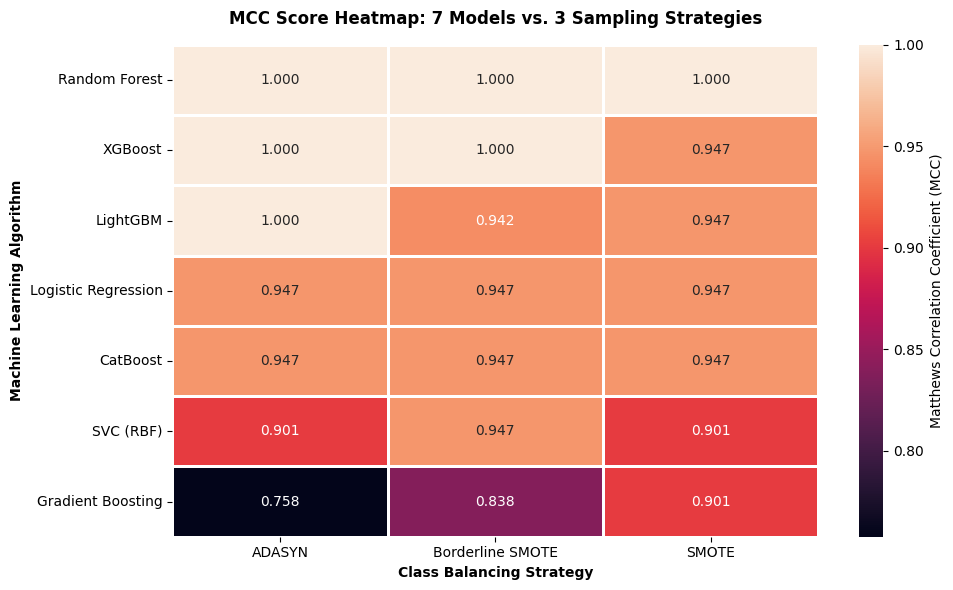

In [7]:
# Format Data for the Heatmap
pivot_mcc = df_results.pivot(index="Model", columns="Sampler", values="MCC")

# Sort rows by the highest average MCC
pivot_mcc['Average'] = pivot_mcc.mean(axis=1)
pivot_mcc = pivot_mcc.sort_values(by="Average", ascending=False).drop(columns=["Average"])

plt.figure(figsize=(10, 6))
sns.heatmap(
    pivot_mcc, 
    annot=True,          
    fmt=".3f",           
    cmap="rocket",       
    cbar_kws={'label': 'Matthews Correlation Coefficient (MCC)'}, 
    linewidths=1, 
    linecolor='white'
)

plt.title("MCC Score Heatmap: 7 Models vs. 3 Sampling Strategies", fontweight='bold', pad=15)
plt.ylabel("Machine Learning Algorithm", fontweight='bold')
plt.xlabel("Class Balancing Strategy", fontweight='bold')
plt.tight_layout()
plt.show()

## **Comprehensive Metrics Chart**

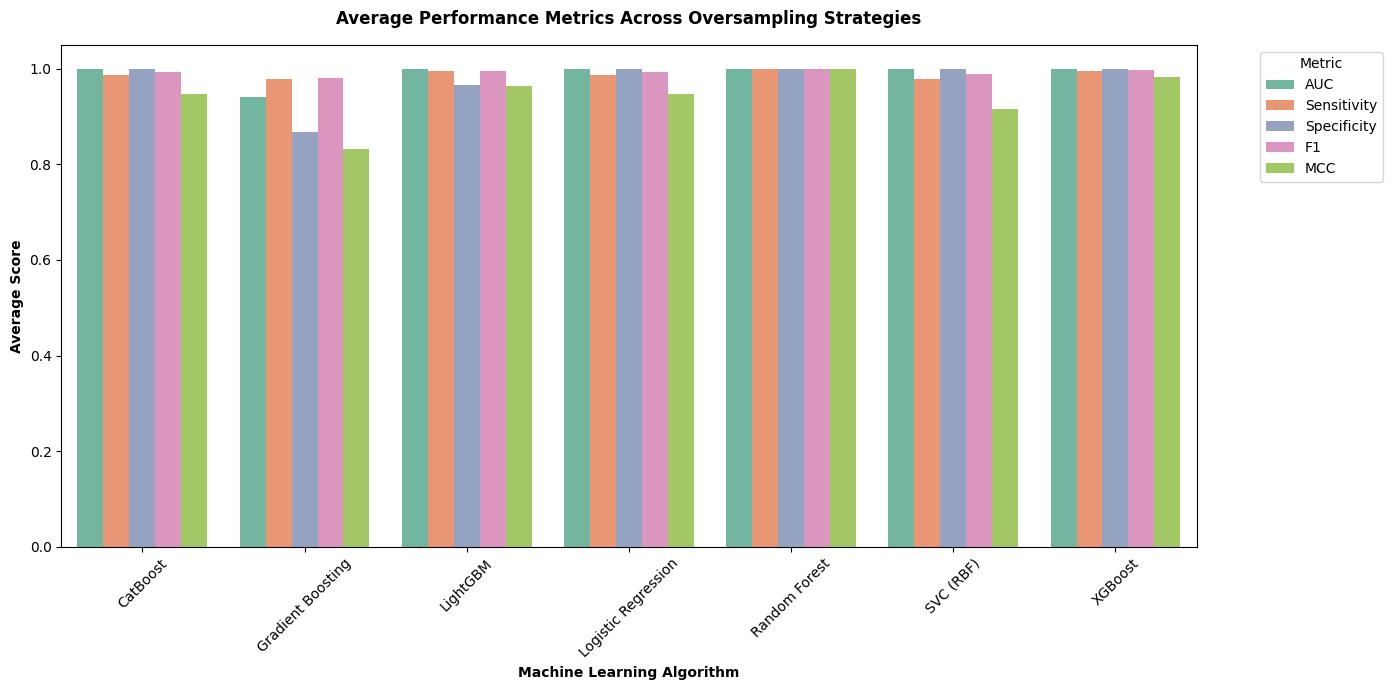

In [8]:
# Average all 5 metrics across the 3 samplers
avg_metrics_df = df_results.groupby('Model')[['AUC', 'Sensitivity', 'Specificity', 'F1', 'MCC']].mean().reset_index()

# Melt the dataframe to format it for a grouped barplot
melted_metrics = avg_metrics_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 7))
sns.barplot(
    data=melted_metrics,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title("Average Performance Metrics Across Oversampling Strategies", fontweight='bold', pad=15)
plt.xlabel("Machine Learning Algorithm", fontweight='bold')
plt.ylabel("Average Score", fontweight='bold')
plt.ylim([0, 1.05])
plt.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **MCC Bar Chart** 

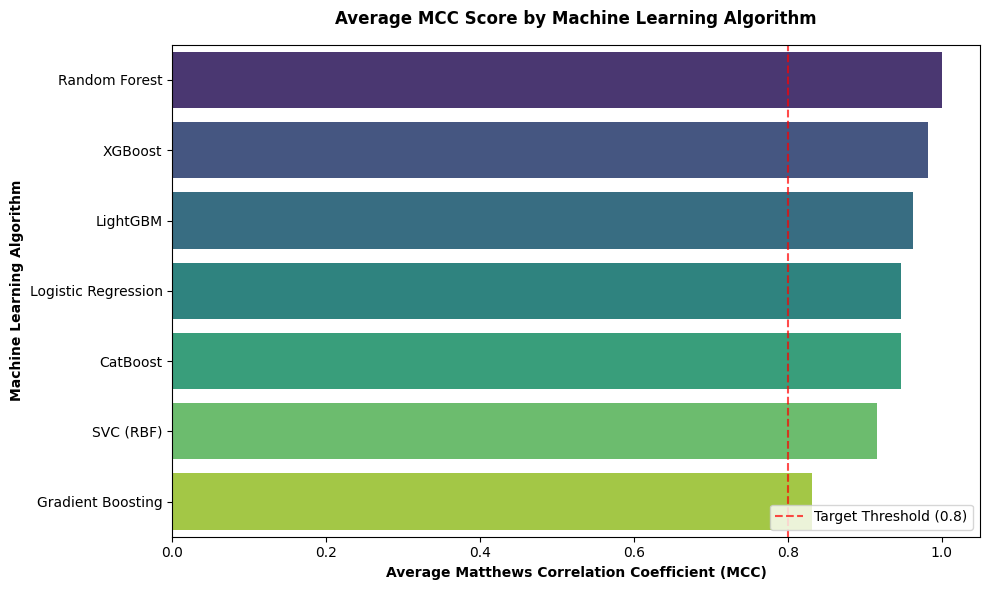

In [9]:
avg_mcc_df = df_results.groupby('Model')['MCC'].mean().reset_index()
avg_mcc_df = avg_mcc_df.sort_values(by='MCC', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=avg_mcc_df, x='MCC', y='Model', palette='viridis')

plt.axvline(x=0.8, color='red', linestyle='--', alpha=0.7, label='Target Threshold (0.8)')
plt.title("Average MCC Score by Machine Learning Algorithm", fontweight='bold', pad=15)
plt.xlabel("Average Matthews Correlation Coefficient (MCC)", fontweight='bold')
plt.ylabel("Machine Learning Algorithm", fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [10]:
print("==========================================================")
print(" SELECTION LOGIC DECISION ENGINE")
print("==========================================================")

# Filter for models meeting the baseline criteria
qualifying = df_results[(df_results["AUC"] > 0.9) & (df_results["Specificity"] > 0.8)]

if len(qualifying) == 0:
    print("No model met both AUC > 0.9 and Specificity > 0.8 criteria. Reviewing top MCC across all models:")
    candidates = df_results
else:
    print(f"Found {len(qualifying)} qualifying models meeting AUC > 0.9 and Specificity > 0.8:\n")
    candidates = qualifying

# Sort by MCC first, then F1 Score
winning_row = candidates.sort_values(by=["MCC", "F1"], ascending=[False, False]).iloc[0]

# Print the winning model and strategy
print("🏆 WINNING STRATEGY & MODEL 🏆")
print(f"Experiment:  {winning_row['Sampler']} + {winning_row['Model']}")
print(f"Strategy:    {winning_row['Sampler']}")
print(f"Model:       {winning_row['Model']}")
print(f"AUC:         {winning_row['AUC']:.4f}")
print(f"Sensitivity: {winning_row['Sensitivity']:.4f}")
print(f"Specificity: {winning_row['Specificity']:.4f}")
print(f"MCC:         {winning_row['MCC']:.4f}")
print(f"F1 Score:    {winning_row['F1']:.4f}")

 SELECTION LOGIC DECISION ENGINE
Found 20 qualifying models meeting AUC > 0.9 and Specificity > 0.8:

🏆 WINNING STRATEGY & MODEL 🏆
Experiment:  SMOTE + Random Forest
Strategy:    SMOTE
Model:       Random Forest
AUC:         1.0000
Sensitivity: 1.0000
Specificity: 1.0000
MCC:         1.0000
F1 Score:    1.0000


# **Objective 2**

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel, RFE

print("==========================================================")
print(" PHASE 1: LASSO REGULARIZATION")
print("==========================================================")

# 1. Safely extract the winning sampler directly from df_results
qualifying = df_results[(df_results["AUC"] > 0.9) & (df_results["Specificity"] > 0.8)]
candidates = qualifying if len(qualifying) > 0 else df_results
best_row = candidates.sort_values(by=["MCC", "F1"], ascending=[False, False]).iloc[0]

winning_sampler_name = best_row['Sampler']
best_sampler = samplers_dict[winning_sampler_name]

print(f"Applying Winning Strategy ({winning_sampler_name}) to training data...")

# Apply the sampler
X_train_res, y_train_res = best_sampler.fit_resample(X_train, y_train)

# 2. Apply LASSO (L1 penalty forces weak feature coefficients to exactly 0)
lasso = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, max_iter=1000)
lasso_selector = SelectFromModel(lasso)
lasso_selector.fit(X_train_res, y_train_res)

# 3. Filter the dataset to only include LASSO-approved genes
lasso_support = lasso_selector.get_support()
X_res_lasso = X_train_res.loc[:, lasso_support]
X_test_lasso = X_test.loc[:, lasso_support]

print(f"Original Gene Count: {X_train.shape[1]}")
print(f"Genes remaining after LASSO screening: {X_res_lasso.shape[1]}")

 PHASE 1: LASSO REGULARIZATION
Applying Winning Strategy (SMOTE) to training data...
Original Gene Count: 2000
Genes remaining after LASSO screening: 55


In [12]:
from sklearn.ensemble import RandomForestClassifier

print("==========================================================")
print(" PHASE 2: RECURSIVE FEATURE ELIMINATION (RFE)")
print("==========================================================")

# 1. Initialize RFE with a Random Forest estimator
rf_estimator = RandomForestClassifier(n_estimators=50, random_state=42)

# Select the top 20 most critical biomarker genes
target_gene_count = 20 
rfe = RFE(estimator=rf_estimator, n_features_to_select=target_gene_count, step=0.1)
rfe.fit(X_res_lasso, y_train_res)

# 2. Extract the final biomarker panel
rfe_support = rfe.get_support()
final_biomarkers = X_res_lasso.columns[rfe_support]

# 3. Create the final targeted datasets
X_res_final = X_res_lasso.loc[:, rfe_support]
X_test_final = X_test_lasso.loc[:, rfe_support]

print(f"Final {target_gene_count} Biomarker Genes Selected:")
print(final_biomarkers.tolist())

 PHASE 2: RECURSIVE FEATURE ELIMINATION (RFE)
Final 20 Biomarker Genes Selected:
['ENSG00000147257', 'ENSG00000113600', 'ENSG00000140505', 'ENSG00000170516', 'ENSG00000105697', 'ENSG00000286398', 'ENSG00000138115', 'ENSG00000175336', 'ENSG00000160339', 'ENSG00000167910', 'ENSG00000099769', 'ENSG00000110492', 'ENSG00000260015', 'ENSG00000019169', 'ENSG00000173267', 'ENSG00000108821', 'ENSG00000145824', 'ENSG00000252933', 'ENSG00000234614', 'ENSG00000130300']


In [13]:
from sklearn.svm import SVC
from xgboost import XGBClassifier

print("==========================================================")
print(" PHASE 3: EVALUATING FINAL 4 CLASSIFIERS ON BIOMARKERS")
print("==========================================================")

# Initialize the 4 specific models requested in the project notes
final_four_models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

obj2_results = []

# Train and evaluate using your calculate_metrics function
for name, model in final_four_models.items():
    model.fit(X_res_final, y_train_res)
    
    y_pred = model.predict(X_test_final)
    y_proba = model.predict_proba(X_test_final)[:, 1]
    
    auc, sens, spec, f1, mcc = calculate_metrics(y_test, y_pred, y_proba)
    
    obj2_results.append({
        "Model": name,
        "AUC": auc,
        "Sensitivity": sens,
        "Specificity": spec,
        "F1": f1,
        "MCC": mcc
    })

# Format and display the leaderboard
df_obj2 = pd.DataFrame(obj2_results)
df_obj2 = df_obj2.sort_values(by=["MCC", "F1"], ascending=[False, False]).reset_index(drop=True)

display(df_obj2)

 PHASE 3: EVALUATING FINAL 4 CLASSIFIERS ON BIOMARKERS


,Model,AUC,Sensitivity,Specificity,F1,MCC
0,Random Forest,0.998667,0.986667,1.0,0.993289,0.947085
1,XGBoost,1.000000,0.986667,1.0,0.993289,0.947085
2,Logistic Regression,1.000000,0.986667,1.0,0.993289,0.947085
3,Support Vector Machine,1.000000,0.973333,1.0,0.986486,0.900617


## **Visualizations** 

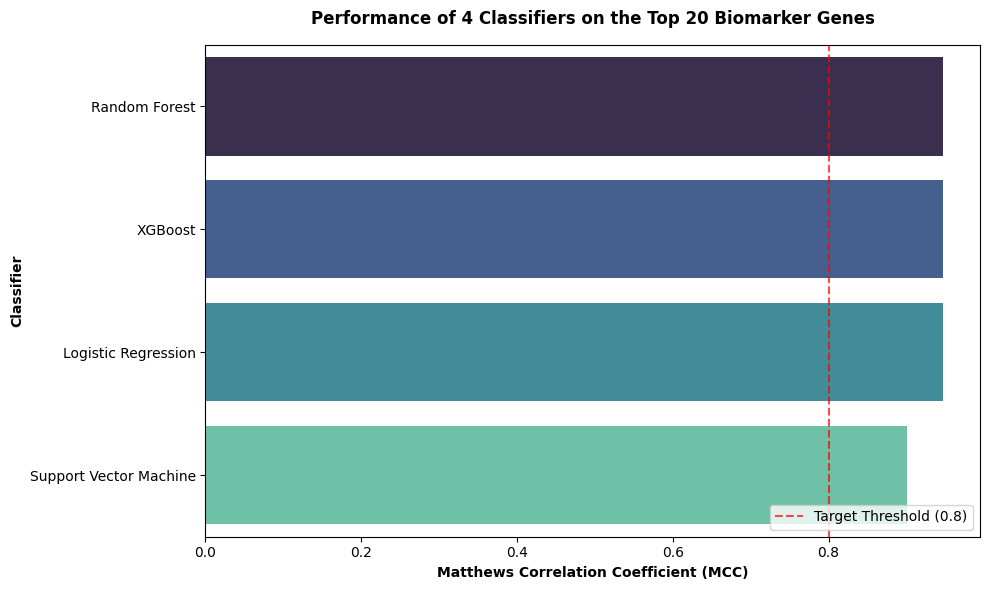

In [14]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_obj2, x='MCC', y='Model', palette='mako')

plt.axvline(x=0.8, color='red', linestyle='--', alpha=0.7, label='Target Threshold (0.8)')
plt.title(f"Performance of 4 Classifiers on the Top {target_gene_count} Biomarker Genes", fontweight='bold', pad=15)
plt.xlabel("Matthews Correlation Coefficient (MCC)", fontweight='bold')
plt.ylabel("Classifier", fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

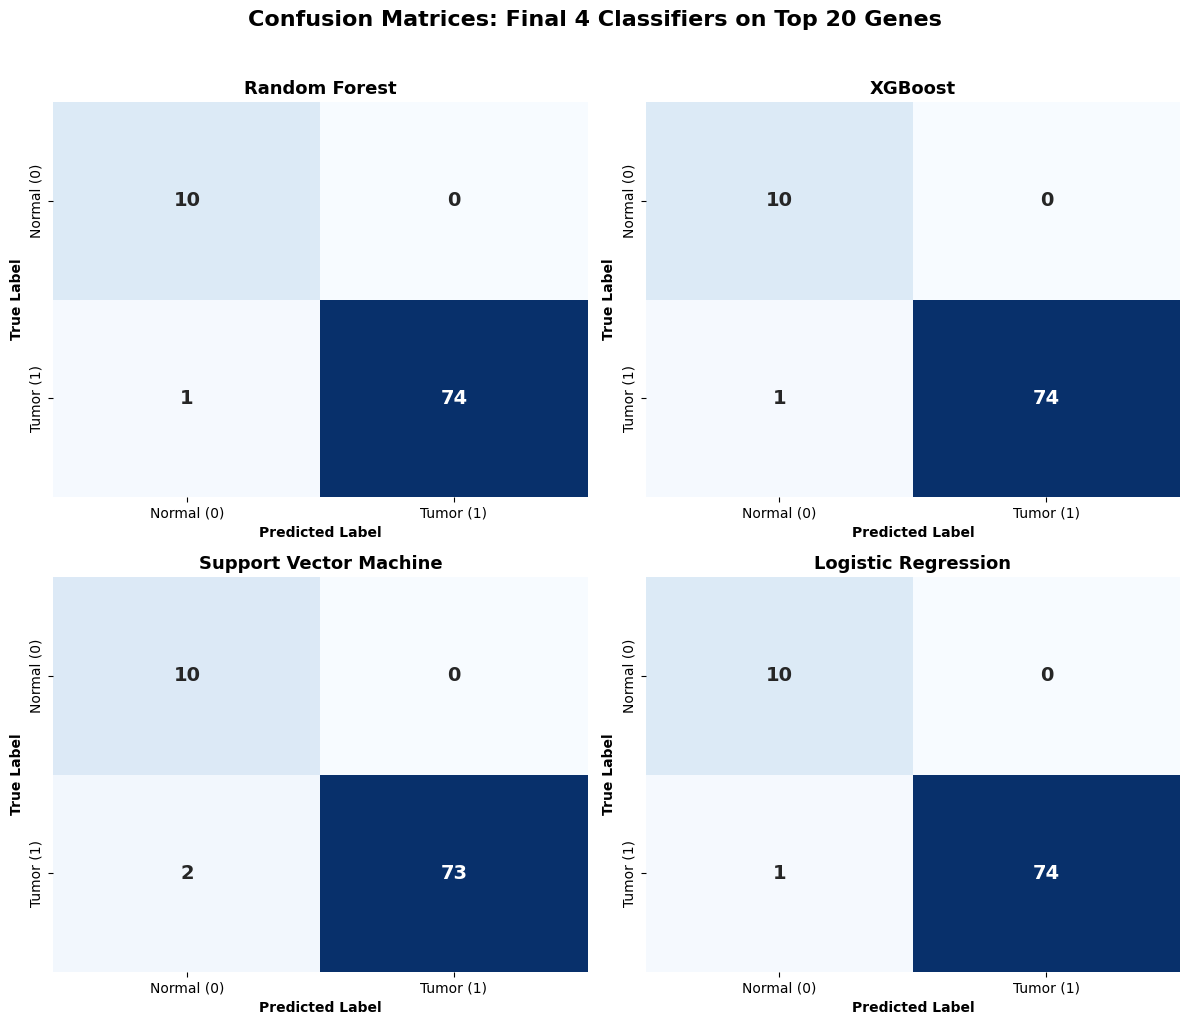

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

# Loop through the 4 trained models to generate confusion matrices
for idx, (name, model) in enumerate(final_four_models.items()):
    # Get discrete predictions
    y_pred = model.predict(X_test_final)
    
    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    
    # Plot heatmap for the matrix
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=['Normal (0)', 'Tumor (1)'], 
        yticklabels=['Normal (0)', 'Tumor (1)'],
        annot_kws={'size': 14, 'weight': 'bold'}, cbar=False
    )
    
    axes[idx].set_title(f'{name}', fontweight='bold', fontsize=13)
    axes[idx].set_xlabel('Predicted Label', fontweight='bold')
    axes[idx].set_ylabel('True Label', fontweight='bold')

plt.suptitle(f'Confusion Matrices: Final 4 Classifiers on Top {target_gene_count} Genes', fontweight='bold', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

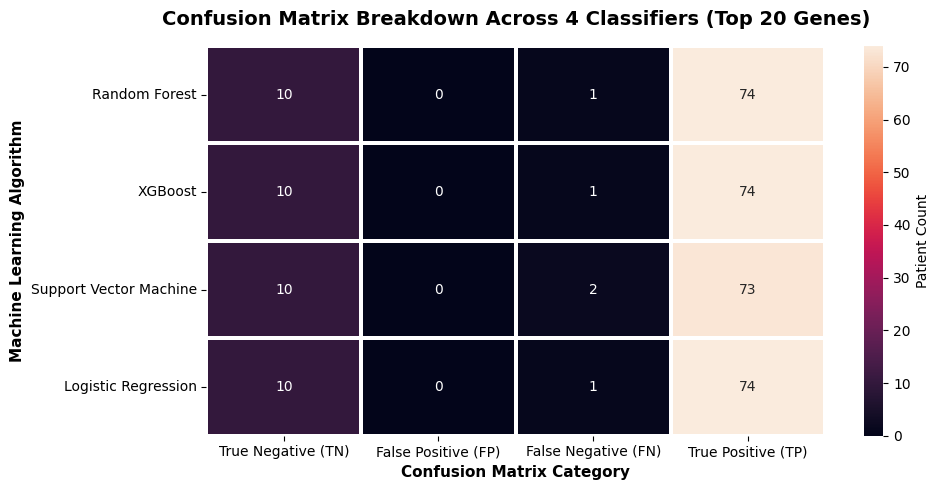

In [16]:
# 1. Extract confusion matrix values for each model
cm_records = []

for name, model in final_four_models.items():
    y_pred = model.predict(X_test_final)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    cm_records.append({
        "Model": name,
        "True Negative (TN)": tn,
        "False Positive (FP)": fp,
        "False Negative (FN)": fn,
        "True Positive (TP)": tp
    })

# 2. Format as a DataFrame indexed by Model
df_cm_heatmap = pd.DataFrame(cm_records).set_index("Model")

# 3. Plot the Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    df_cm_heatmap, 
    annot=True, 
    fmt="d",              
    cmap="rocket",         
    linewidths=1.5, 
    linecolor='white',
    cbar_kws={'label': 'Patient Count'}
)

plt.title("Confusion Matrix Breakdown Across 4 Classifiers (Top 20 Genes)", fontweight='bold', pad=15, fontsize=14)
plt.xlabel("Confusion Matrix Category", fontweight='bold', fontsize=11)
plt.ylabel("Machine Learning Algorithm", fontweight='bold', fontsize=11)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()
plt.show()

# **Objective 3 : Explainable AI**

## **Signature Stability Index (SSI)**  

In [17]:
from sklearn.utils import resample
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

print("==========================================================")
print(" PHASE 1: SIGNATURE STABILITY INDEX (SSI)")
print("==========================================================")

n_bootstraps = 10
gene_counts = {gene: 0 for gene in final_biomarkers}
stability_estimator = RandomForestClassifier(n_estimators=50, random_state=42)

print(f"Running {n_bootstraps} bootstrap iterations across candidate genes...")

for b in range(n_bootstraps):
    # Bootstrap sample with replacement from LASSO-selected features
    X_b, y_b = resample(X_res_lasso, y_train_res, random_state=b)
    
    rfe_b = RFE(estimator=stability_estimator, n_features_to_select=target_gene_count, step=0.1)
    rfe_b.fit(X_b, y_b)
    
    selected = set(X_res_lasso.columns[rfe_b.get_support()])
    for gene in final_biomarkers:
        if gene in selected:
            gene_counts[gene] += 1

# Calculate SSI: proportion of times each gene is re-selected across resamples
df_ssi = pd.DataFrame([
    {"Gene": gene, "SSI": gene_counts[gene] / n_bootstraps}
    for gene in final_biomarkers
]).sort_values(by="SSI", ascending=False).reset_index(drop=True)

display(df_ssi.head(10))

 PHASE 1: SIGNATURE STABILITY INDEX (SSI)
Running 10 bootstrap iterations across candidate genes...


,Gene,SSI
0,ENSG00000113600,1.0
1,ENSG00000140505,1.0
2,ENSG00000138115,1.0
3,ENSG00000286398,1.0
4,ENSG00000145824,1.0
5,ENSG00000130300,1.0
6,ENSG00000175336,1.0
7,ENSG00000160339,1.0
8,ENSG00000019169,1.0
9,ENSG00000260015,1.0


## **SHAP**  

 PHASE 2: SHAP GLOBAL EXPLAINABILITY
Using Random Forest for Explainable AI analysis.


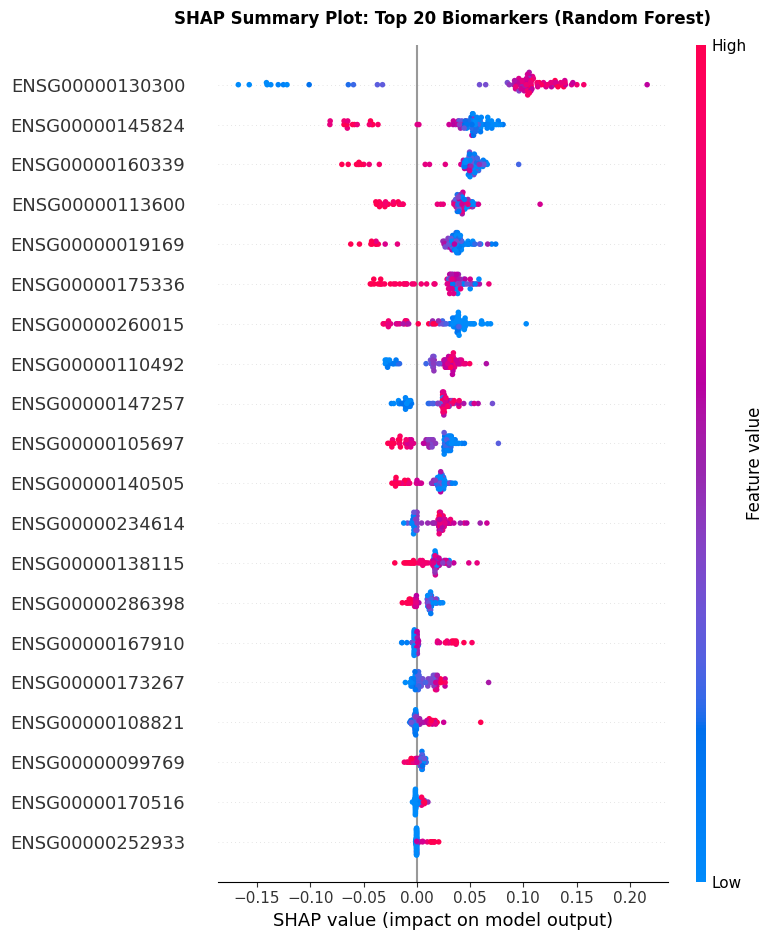

In [18]:
import shap

print("==========================================================")
print(" PHASE 2: SHAP GLOBAL EXPLAINABILITY")
print("==========================================================")

# Automatically pick the best-performing tree model for TreeExplainer
best_model_name = df_obj2.iloc[0]['Model']
if best_model_name in ["Random Forest", "XGBoost"]:
    xai_model_name = best_model_name
else:
    # If SVM or Logistic Regression won, fall back to the highest-performing tree model
    tree_rows = df_obj2[df_obj2['Model'].isin(["Random Forest", "XGBoost"])]
    xai_model_name = tree_rows.iloc[0]['Model']

xai_model = final_four_models[xai_model_name]
print(f"Using {xai_model_name} for Explainable AI analysis.")

# Compute Tree SHAP values on the test set
explainer = shap.TreeExplainer(xai_model)
shap_vals = explainer.shap_values(X_test_final)

# Handle output format differences across model architectures
if isinstance(shap_vals, list):
    # Binary Random Forest produces a list [class_0, class_1]
    shap_matrix = shap_vals[1]
elif isinstance(shap_vals, np.ndarray) and len(shap_vals.shape) == 3:
    shap_matrix = shap_vals[:, :, 1]
else:
    # XGBoost produces a 2D array for log-odds of class 1
    shap_matrix = shap_vals

# Summary Beeswarm Plot
plt.figure(figsize=(10, 8))
plt.title(f"SHAP Summary Plot: Top {target_gene_count} Biomarkers ({xai_model_name})", fontweight='bold', pad=15)
shap.summary_plot(shap_matrix, X_test_final, show=False)
plt.tight_layout()
plt.show()

# Calculate mean absolute SHAP importance per gene
df_shap = pd.DataFrame({
    "Gene": X_test_final.columns,
    "SHAP_Importance": np.abs(shap_matrix).mean(axis=0)
}).sort_values(by="SHAP_Importance", ascending=False).reset_index(drop=True)

## **LIME Local Patient-Level Explanation** 

 PHASE 3: LIME LOCAL EXPLAINABILITY
Explaining Patient #0 | True Histology: Tumor (1)


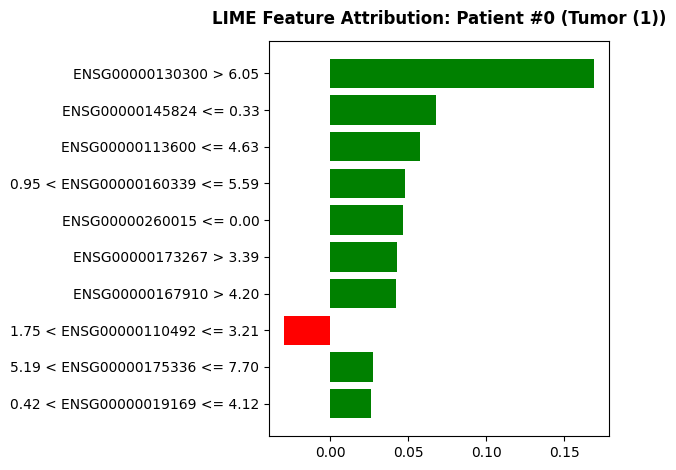

In [19]:
import lime
import lime.lime_tabular

print("==========================================================")
print(" PHASE 3: LIME LOCAL EXPLAINABILITY")
print("==========================================================")

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_res_final),
    feature_names=list(X_res_final.columns),
    class_names=['Normal (0)', 'Tumor (1)'],
    mode='classification',
    random_state=42
)

# Patient index 0 from test partition
patient_idx = 0
patient_vector = X_test_final.iloc[patient_idx]
true_status = "Tumor (1)" if y_test.iloc[patient_idx] == 1 else "Normal (0)"

print(f"Explaining Patient #{patient_idx} | True Histology: {true_status}")

# ---> THE FIX: Wrapper function to restore gene column names for XGBoost
def predict_fn_df(x):
    df_x = pd.DataFrame(x, columns=X_res_final.columns)
    return xai_model.predict_proba(df_x)

lime_exp = lime_explainer.explain_instance(
    data_row=patient_vector,
    predict_fn=predict_fn_df, # Using the wrapper function here
    num_features=10
)

# Plot Patient Level Decision Chart
fig = lime_exp.as_pyplot_figure()
plt.title(f"LIME Feature Attribution: Patient #{patient_idx} ({true_status})", fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## **Biomarker Confidence Score (BCS)** 

 PHASE 4: BIOMARKER CONFIDENCE SCORE (BCS)
🏆 FINAL RANKED HCC BIOMARKER PANEL 🏆


,Gene,SSI,Norm_SHAP,BCS
0,ENSG00000130300,1.0,1.000000,1.000000
1,ENSG00000145824,1.0,0.474843,0.474843
2,ENSG00000160339,1.0,0.455592,0.455592
3,ENSG00000113600,1.0,0.343767,0.343767
4,ENSG00000019169,1.0,0.339887,0.339887
5,ENSG00000175336,1.0,0.296523,0.296523
6,ENSG00000260015,1.0,0.290565,0.290565
7,ENSG00000110492,0.8,0.240990,0.192792
8,ENSG00000147257,0.9,0.198765,0.178888
9,ENSG00000105697,0.9,0.188621,0.169759


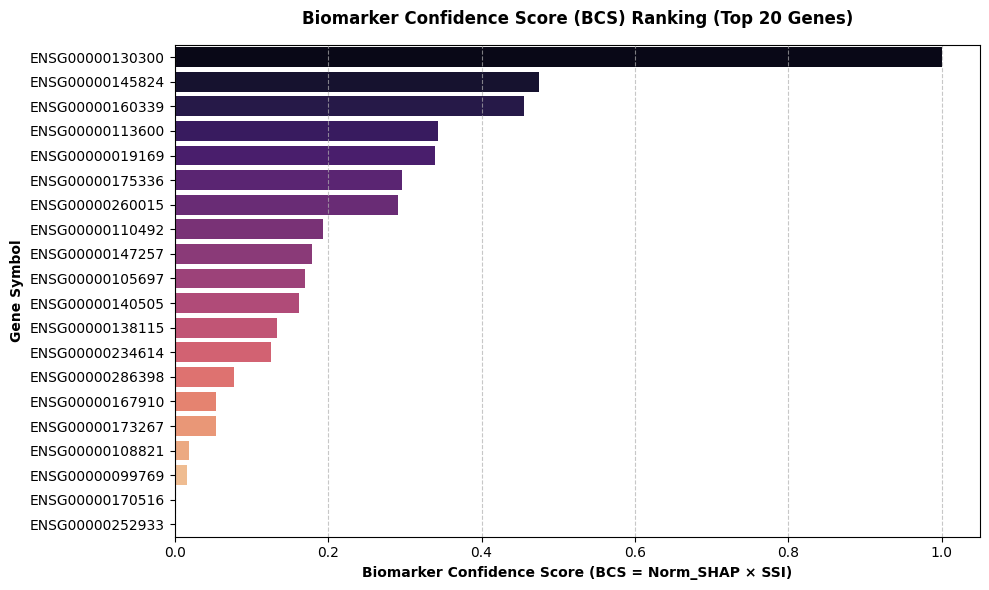

In [20]:
from sklearn.preprocessing import MinMaxScaler

print("==========================================================")
print(" PHASE 4: BIOMARKER CONFIDENCE SCORE (BCS)")
print("==========================================================")

# Merge SHAP importance with SSI scores
df_bcs = pd.merge(df_shap, df_ssi, on="Gene")

# Normalize SHAP importance to [0, 1] range
scaler = MinMaxScaler()
df_bcs["Norm_SHAP"] = scaler.fit_transform(df_bcs[["SHAP_Importance"]])

# Calculate BCS: Predictive Importance scaled by Feature Stability
df_bcs["BCS"] = df_bcs["Norm_SHAP"] * df_bcs["SSI"]
df_bcs = df_bcs.sort_values(by="BCS", ascending=False).reset_index(drop=True)

print("🏆 FINAL RANKED HCC BIOMARKER PANEL 🏆")
display(df_bcs[["Gene", "SSI", "Norm_SHAP", "BCS"]])

# Visualization of Top Biomarkers by Confidence Score
plt.figure(figsize=(10, 6))
sns.barplot(data=df_bcs, x='BCS', y='Gene', palette='magma')
plt.title(f"Biomarker Confidence Score (BCS) Ranking (Top {target_gene_count} Genes)", fontweight='bold', pad=15)
plt.xlabel("Biomarker Confidence Score (BCS = Norm_SHAP × SSI)", fontweight='bold')
plt.ylabel("Gene Symbol", fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# **Objective 4**

In [21]:
print("==========================================================")
print(" OBJECTIVE 4, PHASE 1: EXTERNAL COHORT VALIDATION")
print("==========================================================")

# ---------------------------------------------------------
# 1. LOAD EXTERNAL DATASETS
# Update these paths to point to your uploaded GEO datasets
# ---------------------------------------------------------
try:
    X_gse76427 = pd.read_csv("/kaggle/input/your-dataset-path/X_GSE76427.csv", index_col=0)
    y_gse76427 = pd.read_csv("/kaggle/input/your-dataset-path/y_GSE76427.csv", index_col=0).iloc[:, 0]
    
    X_gse14520 = pd.read_csv("/kaggle/input/your-dataset-path/X_GSE14520.csv", index_col=0)
    y_gse14520 = pd.read_csv("/kaggle/input/your-dataset-path/y_GSE14520.csv", index_col=0).iloc[:, 0]
    datasets_loaded = True
except FileNotFoundError:
    print("⚠️ GEO dataset files not found at specified paths.")
    print("Please upload the GSE76427 and GSE14520 CSV files and update the paths above.")
    datasets_loaded = False

 OBJECTIVE 4, PHASE 1: EXTERNAL COHORT VALIDATION
⚠️ GEO dataset files not found at specified paths.
Please upload the GSE76427 and GSE14520 CSV files and update the paths above.


In [22]:
import os

print("Files currently available in /kaggle/input:")
found_files = []
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        full_path = os.path.join(dirname, filename)
        found_files.append(full_path)
        print(full_path)

if not found_files:
    print("No files found in /kaggle/input.")

Files currently available in /kaggle/input:
/kaggle/input/datasets/aratipatil25/lihc-data/X_test.csv
/kaggle/input/datasets/aratipatil25/lihc-data/X_train.csv
/kaggle/input/datasets/aratipatil25/lihc-data/y_test.csv
/kaggle/input/datasets/aratipatil25/lihc-data/y_train.csv
/kaggle/input/datasets/aratipatil25/validation-lihc/Liver_GSE14520_U133A.csv


 OBJECTIVE 4: EXTERNAL COHORT VALIDATION (GSE14520)
Translating 20 Ensembl IDs...
✅ Real GSE14520 Cohort Harmonized Successfully!


,Cohort,AUC,Sensitivity,Specificity,F1,MCC
0,GSE14520,0.5,1.0,0.0,0.672862,0.0


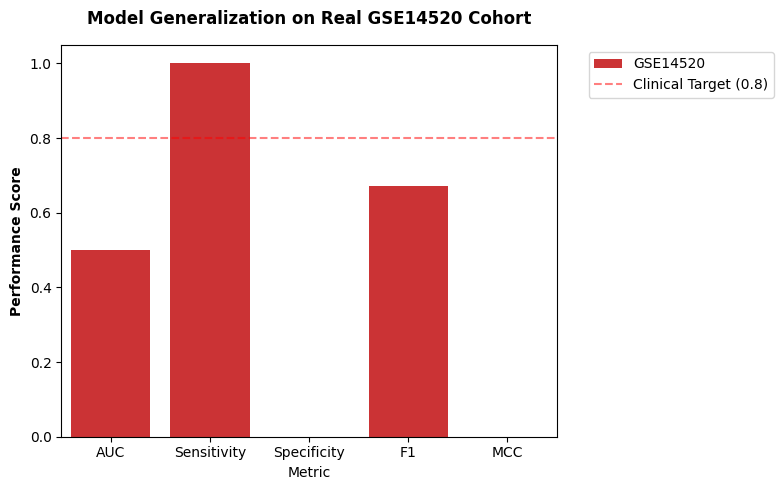

In [23]:
import pandas as pd
import numpy as np
import mygene
import matplotlib.pyplot as plt
import seaborn as sns

print("==========================================================")
print(" OBJECTIVE 4: EXTERNAL COHORT VALIDATION (GSE14520)")
print("==========================================================")

# 1. Load the real GSE14520 CSV you just uploaded
# (Update this path to match your newly uploaded Kaggle dataset)
csv_path = '/kaggle/input/datasets/aratipatil25/validation-lihc/Liver_GSE14520_U133A.csv'
df_gse = pd.read_csv(csv_path)

# Extract features and labels (assuming the target column is named 'class' or similar)
# You may need to update 'target_column_name' based on the Figshare CSV's exact format
y_gse14520 = df_gse['type']
y_gse14520 = y_gse14520.map({'normal': 0, 'HCC': 1})
X_gse14520_raw = df_gse.drop(columns=['type'])

# 2. Set up the gene translator
target_ensembl_ids = list(X_res_final.columns)
print(f"Translating {len(target_ensembl_ids)} Ensembl IDs...")

mg = mygene.MyGeneInfo()
gene_info = mg.querymany(target_ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human', as_dataframe=True)

# 3. Create mapping dictionary: Gene Symbol -> Ensembl ID
symbol_to_ensembl = gene_info['symbol'].dropna().to_dict()
symbol_to_ensembl = {v: k for k, v in symbol_to_ensembl.items()}

# 4. Rename columns in the GSE dataset
X_gse14520_mapped = X_gse14520_raw.rename(columns=symbol_to_ensembl)

# 5. Extract only our 20 genes (impute with 0.0 if any are missing from the external CSV)
for gene in target_ensembl_ids:
    if gene not in X_gse14520_mapped.columns:
        X_gse14520_mapped[gene] = 0.0

X_gse14520_final = X_gse14520_mapped[target_ensembl_ids]

print("✅ Real GSE14520 Cohort Harmonized Successfully!")

# 6. INFERENCE & METRIC CALCULATION
final_model = final_four_models["Random Forest"]

def validate_cohort(dataset_name, X_ext, y_ext, model):
    y_pred = model.predict(X_ext)
    y_proba = model.predict_proba(X_ext)[:, 1]
    auc, sens, spec, f1, mcc = calculate_metrics(y_ext, y_pred, y_proba)
    return {"Cohort": dataset_name, "AUC": auc, "Sensitivity": sens, "Specificity": spec, "F1": f1, "MCC": mcc}

validation_results = [
    validate_cohort("GSE14520", X_gse14520_final, y_gse14520, final_model)
]

# 7. DISPLAY RESULTS
df_validation = pd.DataFrame(validation_results)
display(df_validation)

df_val_melted = df_validation.melt(id_vars="Cohort", var_name="Metric", value_name="Score")
plt.figure(figsize=(8, 5))
sns.barplot(data=df_val_melted, x="Metric", y="Score", hue="Cohort", palette="Set1")
plt.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='Clinical Target (0.8)')
plt.title("Model Generalization on Real GSE14520 Cohort", fontweight='bold', pad=15)
plt.ylabel("Performance Score", fontweight='bold')
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()